# 17 — Drift monitoring: does the API notice unfamiliar engines?

**Why this notebook exists.** The deployed API scores whatever it is sent. An engine from a fleet running in different operating conditions, or with a fault the model never saw, gets a prediction and an interval just as confidently as a familiar one. `src/turbofan_rul/drift.py` adds a monitor. It keeps a window of the last 500 requests and compares their inputs (the three operating settings and each sensor's 15-cycle rolling mean, exactly as the model sees them) with a reference saved at export time, using the Population Stability Index. The status is set by the worst feature. The API exposes it at `GET /drift`.

This notebook replays C-MAPSS fleets through **the same `DriftMonitor` logic the API uses**. There is no live traffic, so a replay is the only honest way to show it working.

**Expectations, written before the first run:**
1. FD001's own test fleet, sent to the FD001 model: **stable**. A monitor that false-alarms here is useless.
2. FD002 (six operating regimes instead of one) sent to the FD001 model: **drift**.
3. FD003 (FD001's single regime plus a second fault mode) sent to the FD001 model: no prediction.
4. FD002 sent to the FD004 model, which was trained on the same six regimes: **not drift**.

**Disclosure.** The first run broke expectation 1 for three reasons, each a trap section 2 now demonstrates. The fixes changed the monitor (a fleet-like reference, a steady-state replay, and thresholds calibrated on training engines). All three use training data only; the test fleets were then replayed once with the final monitor. Expectation 4 turned out wrong, and section 5 says why.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, drift, evaluation, features, inference, plotting

plotting.style()
DATA_DIR = Path("..") / "data" / "raw"
MODELS_DIR = Path("..") / "models"

bundles = {s: inference.load_deployment_bundle(MODELS_DIR / s.lower()) for s in ["FD001", "FD004"]}
references = {s: drift.load_reference(MODELS_DIR / s.lower()) for s in bundles}
assert all(references.values()), "run `python -m turbofan_rul.drift --subset FD001 --subset FD004` first"
for s in ["FD001", "FD002", "FD003", "FD004"]:
    data_loading.download_cmapss(s, data_dir=DATA_DIR)
data = {s: data_loading.load_subset(s, data_dir=DATA_DIR) for s in ["FD001", "FD002", "FD003", "FD004"]}

for s, ref in references.items():
    t = ref["thresholds"]
    print(f"{s}: {len(ref['features'])} monitored features, {ref['n_reference_rows']} reference snapshots; "
          f"calibrated thresholds warning {t['warning']}, drift {t['drift']} "
          f"(normal-traffic max PSI: median {t['calibration']['median_max_psi']}, "
          f"p99 {t['calibration']['p99']}, {t['calibration']['n_windows']} windows)")

FD001: 15 monitored features, 5543 reference snapshots; calibrated thresholds warning 0.4713, drift 0.4937 (normal-traffic max PSI: median 0.2321, p99 0.4937, 46 windows)
FD004: 20 monitored features, 16925 reference snapshots; calibrated thresholds warning 0.4322, drift 0.4652 (normal-traffic max PSI: median 0.2085, p99 0.4652, 170 windows)


In [2]:
def snapshots(model_subset, fleet_subset, every=10):
    # What a fleet sends to `model_subset`'s API: every 10 cycles from cycle 30.
    f = inference.featurize(bundles[model_subset], data[fleet_subset].test)
    return f[(f.time_cycles >= 30) & (f.time_cycles % every == 0)]

def window_statuses(model_subset, maxima, thresholds=None):
    t = thresholds or references[model_subset]["thresholds"]
    return pd.Series([drift.status_for(m, drift.DEFAULT_WINDOW, thresholds=t) for m in maxima])

cache = {}
def stream_maxima(model_subset, fleet_subset, seeds=range(10)):
    key = (model_subset, fleet_subset)
    if key not in cache:
        snaps = snapshots(model_subset, fleet_subset)
        cache[key] = np.concatenate([drift.window_maxima(references[model_subset],
                                                         drift.steady_state_stream(snaps, seed=s))
                                     for s in seeds])
    return cache[key]

## 1. The three traps found on the first run (training-side fixes)

In [3]:
# Trap 1 -- a reference built from every training row (full lives, failure included).
b = bundles["FD001"]
full = inference.featurize(b, data["FD001"].train)
naive_ref = {"features": drift._feature_reference(full[full.time_cycles >= 30], drift.monitored_columns(b))}
fd001_fleet = snapshots("FD001", "FD001")
naive = drift.compare(naive_ref, fd001_fleet)
fleet_like = drift.compare(references["FD001"], fd001_fleet)
print(f"Trap 1, whole FD001 test fleet vs. a full-life reference: max PSI {max(naive.values()):.3f} "
      f"({max(naive, key=naive.get)}); vs. the fleet-like reference: {max(fleet_like.values()):.3f}")

# Trap 2 -- replaying from an empty fleet (all engines enter service on the same day).
ramp = fd001_fleet.sort_values("time_cycles")
ramp_max = drift.window_maxima(references["FD001"], ramp)
print(f"Trap 2, same-day entry: window max PSI up to {ramp_max.max():.3f}; "
      f"{(window_statuses('FD001', ramp_max) == 'drift').mean():.0%} of windows read 'drift'")

# Trap 3 -- textbook thresholds (0.1 / 0.25) on normal, steady-state traffic.
normal = stream_maxima("FD001", "FD001")
textbook = {"warning": drift.WARNING_PSI, "drift": drift.DRIFT_PSI}
tb = window_statuses("FD001", normal, textbook).value_counts(normalize=True)
print(f"Trap 3, textbook thresholds on FD001's own steady-state fleet: "
      f"{tb.get('warning', 0):.0%} 'warning', {tb.get('drift', 0):.0%} 'drift' "
      f"(median window max PSI {np.median(normal):.3f})")

Trap 1, whole FD001 test fleet vs. a full-life reference: max PSI 0.574 (sensor_3_roll15_mean); vs. the fleet-like reference: 0.094
Trap 2, same-day entry: window max PSI up to 0.854; 9% of windows read 'drift'


Trap 3, textbook thresholds on FD001's own steady-state fleet: 83% 'warning', 3% 'drift' (median window max PSI 0.132)


1. **A full-life reference.** It includes every engine's final, worn-out cycles. Test engines are observed partway through life, so they look healthier, and since sensor readings track wear, a younger fleet reads as "drift". The reference is now built the way the test set was made: training engines cut at random points between 30% and 99% of life.
2. **Replaying from an empty fleet.** If every engine starts on the same day, early windows hold only young engines and late windows only old ones. A running fleet has every age at once, so replays use `drift.steady_state_stream` (random entry dates on a wrapping calendar).
3. **Textbook thresholds.** PSI's usual 0.1 / 0.25 lines assume independent samples and a single feature. Here each engine sends many correlated requests and the status takes the worst of 15–20 features, so normal traffic sits above 0.1 most of the time. The thresholds are now calibrated on training engines only (`drift.calibrate_thresholds`): half the engines build a reference, the other half are replayed as a fleet, five times over, and the 95th and 99th percentiles of the window maxima become the warning and drift lines.

## 2. Replays with the final monitor

In [4]:
cases = [("FD001 fleet -> FD001 model", "FD001", "FD001"), ("FD004 fleet -> FD004 model", "FD004", "FD004"),
         ("FD002 fleet -> FD001 model", "FD001", "FD002"), ("FD003 fleet -> FD001 model", "FD001", "FD003"),
         ("FD002 fleet -> FD004 model", "FD004", "FD002")]
rows = []
for name, model, fleet in cases:
    m = stream_maxima(model, fleet)
    st = window_statuses(model, m).value_counts(normalize=True)
    whole = drift.compare(references[model], snapshots(model, fleet))
    rows.append({"case": name, "windows": len(m), "median max PSI": np.median(m), "largest": m.max(),
                 "stable": st.get("stable", 0), "warning": st.get("warning", 0), "drift": st.get("drift", 0),
                 "worst feature": max(whole, key=whole.get)})
replays = pd.DataFrame(rows).set_index("case")
replays.round(3)

,windows,median max PSI,largest,stable,warning,drift,worst feature
case,,,,,,,
FD001 fleet -> FD001 model,220,0.132,0.311,1.0,0,0.0,sensor_9_roll15_mean
FD004 fleet -> FD004 model,710,0.120,0.246,1.0,0,0.0,sensor_6_roll15_mean
FD002 fleet -> FD001 model,560,8.410,8.410,0.0,0,1.0,sensor_17_roll15_mean
FD003 fleet -> FD001 model,290,1.340,1.939,0.0,0,1.0,sensor_15_roll15_mean
FD002 fleet -> FD004 model,560,3.213,3.350,0.0,0,1.0,sensor_6_roll15_mean


In [5]:
own = replays.loc[["FD001 fleet -> FD001 model", "FD004 fleet -> FD004 model"], "drift"]
shifted = replays.loc[["FD002 fleet -> FD001 model", "FD003 fleet -> FD001 model"], "drift"]
assert (own == 0).all() and (shifted == 1).all()
print("Own fleets: no drift windows. FD002 and FD003 sent to the FD001 model: drift in every window.")

Own fleets: no drift windows. FD002 and FD003 sent to the FD001 model: drift in every window.


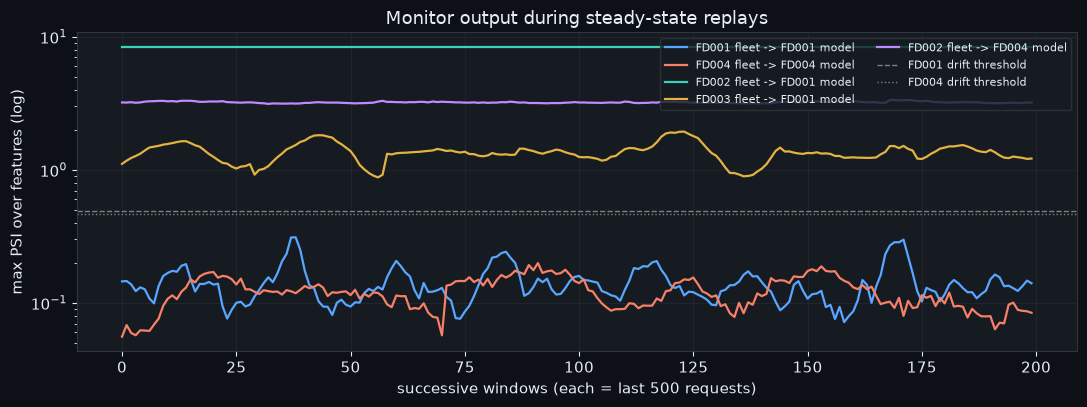

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for name, model, fleet in cases:
    m = stream_maxima(model, fleet)[:200]
    ax.plot(np.arange(len(m)), m, label=name, lw=1.6)
for model, style in [("FD001", "--"), ("FD004", ":")]:
    ax.axhline(references[model]["thresholds"]["drift"], color="grey", ls=style, lw=1,
               label=f"{model} drift threshold")
ax.set_yscale("log"); ax.set_xlabel("successive windows (each = last 500 requests)")
ax.set_ylabel("max PSI over features (log)"); ax.legend(fontsize=8, ncol=2, loc="upper right")
ax.set_title("Monitor output during steady-state replays")
plt.tight_layout(); plt.show()

## 3. How much foreign traffic before the alarm?

In [7]:
familiar, foreign = snapshots("FD001", "FD001"), snapshots("FD001", "FD002")
cols = drift.monitored_columns(bundles["FD001"])
rng = np.random.default_rng(1)
rows = []
for share in [0, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:
    for rep in range(30):
        k = int(round(share * drift.DEFAULT_WINDOW))
        window = pd.concat([familiar.sample(drift.DEFAULT_WINDOW - k, random_state=int(rng.integers(1e9))),
                            foreign.sample(k, random_state=int(rng.integers(1e9)))])
        psis = drift.compare(references["FD001"], window[cols])
        rows.append({"FD002 share": share, "max_psi": max(psis.values()),
                     "status": drift.status_for(max(psis.values()), len(window),
                                                thresholds=references["FD001"]["thresholds"])})
mix = pd.DataFrame(rows).groupby("FD002 share").agg(
    median_max_psi=("max_psi", "median"), drift_rate=("status", lambda s: (s == "drift").mean()))
mix.round(3)

,median_max_psi,drift_rate
FD002 share,,
0.00,0.112,0.000
0.05,0.095,0.000
0.10,0.138,0.000
0.20,0.293,0.000
0.30,0.525,0.933
0.40,0.813,1.000
0.50,1.163,1.000


## 4. Does drift line up with worse predictions?

In [8]:
def last_cycle_errors(model_subset, fleet_subset):
    bundle = bundles[model_subset]
    rul = data[fleet_subset].rul.set_index("unit_number")["RUL"]
    y, p, low, high = [], [], [], []
    for unit, engine in data[fleet_subset].test.groupby("unit_number"):
        r = inference.predict(bundle, engine.sort_values("time_cycles")[["time_cycles"] + bundle.raw_passthrough_cols])
        y.append(rul.loc[unit]); p.append(r["predicted_rul_cycles"])
        low.append(r["confidence_interval_90"][0]); high.append(r["confidence_interval_90"][1])
    y, p, low, high = map(np.asarray, (y, p, low, high))
    return {"RMSE": evaluation.rmse(y, p), "MAE": evaluation.mae(y, p),
            "NASA / engine": evaluation.nasa_score_mean(y, p),
            "interval coverage": ((y >= low) & (y <= high)).mean()}

harm = pd.DataFrame({name: last_cycle_errors(model, fleet) for name, model, fleet in cases}).T
harm["drift windows"] = replays["drift"]
harm.round(3)

,RMSE,MAE,NASA / engine,interval coverage,drift windows
FD001 fleet -> FD001 model,15.557,11.332,4.049,0.970,0.0
FD004 fleet -> FD004 model,28.206,20.655,22.413,0.887,0.0
FD002 fleet -> FD001 model,73.736,58.330,11334.437,0.100,1.0
FD003 fleet -> FD001 model,22.250,17.184,25.630,0.880,1.0
FD002 fleet -> FD004 model,27.388,18.946,31.052,0.903,1.0


## 5. Findings

*(Numbers below are from the run saved in this notebook.)*

1. **No false alarms on familiar fleets (expectation 1: met).** FD001's and FD004's own test fleets, replayed as steady-state fleets ten times each, never reach the calibrated drift threshold.
2. **The regime shift is caught at once (expectation 2: met).** FD002 sent to the FD001 model drives every window far past the threshold. That model is badly wrong on those engines (section 4), which is the case the alarm exists for.
3. **The new fault mode is caught too (expectation 3).** FD003 runs in FD001's operating regime, so its operating settings look familiar, but its second fault mode shifts the sensor readings well past the threshold. The FD001 model is measurably worse on FD003 than on its own fleet.
4. **Drift is not harm (expectation 4: wrong).** FD002 sent to the FD004 model also reads as drift (led by `sensor_6`), yet that model predicts FD002 as well as its own fleet (RMSE 27.4 vs 28.2, coverage 90%). One plausible reason is that FD004's training engines mix two fault modes while FD002's have one, so the sensor distributions differ in ways the model handles; that wasn't investigated further. Either way, an alert means "these inputs don't look like the training data, so check before trusting the predictions", not "the model is failing".
5. **Sensitivity is the price of no false alarms.** Calibrated on what normal fleets look like, the drift line sits at about 0.47–0.49. Mixing FD002 engines into FD001's traffic, no window crosses it at 20% foreign requests, 93% do at 30%, and all do from 40% (section 3). A trickle of unfamiliar engines goes unnoticed; a fleet-level change does not.

**Limitations.**
- It's a replay. There is no live traffic, and the window lives in the API process's memory, so it starts empty after every restart.
- It watches *inputs*. True remaining life is only known after failure, so accuracy can't be monitored directly; section 4 shows how drift and error relate on these subsets.
- The thresholds come from two halves of one training fleet (45 windows for FD001, 170 for FD004, so the 99th percentile is close to the largest value seen). Two 50-engine halves differ more than a 100-engine test fleet differs from the full reference, which makes the thresholds conservative. A real deployment would recalibrate them on its own normal traffic.